# 04 — Modelado: regresión clásica y espacial

Modelamos el **% de voto a Sheinbaum** como función de los indicadores socioeconómicos. Comparamos:

1. **MCO** (statsmodels) con errores estándar robustos (White).
2. **Modelo espacial lag** (SAR) y **espacial error** (SEM) con `spreg`, que incorporan la dependencia espacial detectada en el notebook 03.

In [1]:
import sys, os
sys.path.insert(0, os.path.join("..", "src"))
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

BASE = os.path.join("..")
PROCESADOS = os.path.join(BASE, "data", "processed")
FIGURAS = os.path.join(BASE, "figuras")
os.makedirs(FIGURAS, exist_ok=True)

df = pd.read_csv(os.path.join(PROCESADOS, "municipios_electoral_social.csv"),
                 dtype={"cvegeo": str})
gdf = gpd.read_file(os.path.join(PROCESADOS, "municipios_cartografia_simplificada.gpkg"))
gdf["cvegeo"] = gdf["cvegeo"].str.zfill(5)
gdf = gdf.merge(df, on="cvegeo", how="left")
print(f"{len(df)} municipios con datos, {len(gdf)} polígonos")
gdf.head(3)
import statsmodels.formula.api as smf
from libpysal.weights import Queen
from esda.moran import Moran
from spreg import ML_Lag, ML_Error


2469 municipios con datos, 2478 polígonos


In [2]:
d = df.dropna(subset=["pct_sheinbaum", "pct_participacion"]).reset_index(drop=True)
d["pob_total_log"] = np.log10(d["pob_total"])

formula = ("pct_sheinbaum ~ pct_analfabeta + pct_sin_basica + pct_rural + "
           "pct_ingresos_bajos + pct_hacinamiento + pct_participacion + pob_total_log")
mco = smf.ols(formula, data=d).fit(cov_type="HC1")
print(mco.summary())

                            OLS Regression Results                            
Dep. Variable:          pct_sheinbaum   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.273
Method:                 Least Squares   F-statistic:                     131.1
Date:                Fri, 13 Nov 2026   Prob (F-statistic):          2.85e-164
Time:                        19:09:39   Log-Likelihood:                -9753.9
No. Observations:                2462   AIC:                         1.952e+04
Df Residuals:                    2454   BIC:                         1.957e+04
Df Model:                           7                                         
Covariance Type:                  HC1                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             71.9514      4

In [3]:
g = gdf.dropna(subset=["pct_sheinbaum", "pct_participacion",
                      "pct_analfabeta", "pct_sin_basica", "pct_rural",
                      "pct_ingresos_bajos", "pct_hacinamiento", "pob_total"]).reset_index(drop=True)
g["pob_total_log"] = np.log10(g["pob_total"])
w = Queen.from_dataframe(g, use_index=False)
w.transform = "r"

y = g[["pct_sheinbaum"]].values
X = g[["pct_analfabeta", "pct_sin_basica", "pct_rural",
       "pct_ingresos_bajos", "pct_hacinamiento", "pct_participacion",
       "pob_total_log"]].values
names = ["analfabeta", "sin_basica", "rural", "ingresos_bajos",
         "hacinamiento", "participacion", "pob_log"]

mi_res = Moran(mco.resid, w, permutations=999)
print(f"Moran sobre residuos MCO: I = {mi_res.I:.3f}, p = {mi_res.p_sim:.4f}")
print("(residuos espacialmente autocorrelacionados -> conviene modelo espacial)\n")

sar = ML_Lag(y, X, w=w, name_y="pct_sheinbaum", name_x=names, name_w="queen")
print(sar.summary)

/home/appuser/.local/lib/python3.12/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 7 disconnected components.
 There are 5 islands with ids: 1210, 1276, 1277, 2027, 2030.
  W.__init__(self, neighbors, ids=ids, **kw)


('WARNING: ', 1210, ' is an island (no neighbors)')
('WARNING: ', 1276, ' is an island (no neighbors)')
('WARNING: ', 1277, ' is an island (no neighbors)')
('WARNING: ', 2027, ' is an island (no neighbors)')
('WARNING: ', 2030, ' is an island (no neighbors)')
Moran sobre residuos MCO: I = 0.219, p = 0.0010
(residuos espacialmente autocorrelacionados -> conviene modelo espacial)



ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       queen
Dependent Variable  :pct_sheinbaum                Number of Observations:        2462
Mean dependent var  :     68.5589                Number of Variables   :           9
S.D. dependent var  :     14.9335                Degrees of Freedom    :        2453
Pseudo R-squared    :      0.4553
Spatial Pseudo R-squared:  0.3238
Log likelihood      :  -9479.0911
Sigma-square ML     :    122.1254                Akaike info criterion :   18976.182
S.E of regression   :     11.0510                Schwarz criterion     :   19028.461

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------

In [4]:
sem = ML_Error(y, X, w=w, name_y="pct_sheinbaum", name_x=names, name_w="queen")
print(sem.summary)

/home/appuser/.local/lib/python3.12/site-packages/spreg/ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :       queen
Dependent Variable  :pct_sheinbaum                Number of Observations:        2462
Mean dependent var  :     68.5589                Number of Variables   :           8
S.D. dependent var  :     14.9335                Degrees of Freedom    :        2454
Pseudo R-squared    :      0.2679
Log likelihood      :  -9507.5914
Sigma-square ML     :    122.3003                Akaike info criterion :   19031.183
S.E of regression   :     11.0589                Schwarz criterion     :   19077.653

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------------------------------------------------------------

In [5]:
comparacion = pd.DataFrame({
    "MCO": dict(zip(names, mco.params[1:])),
    "SAR (lag)": dict(zip(names, sar.betas.flatten()[1:-1])),
    "SEM (error)": dict(zip(names, sem.betas.flatten()[1:-1])),
})
display(comparacion.round(3))
print(f"Rho (autorregresión espacial, SAR): {sar.rho:.3f}")
print(f"Lambda (error espacial, SEM): {sem.lam:.3f}")
print(f"AIC -> MCO: {mco.aic:.0f} | SAR: {sar.aic:.0f} | SEM: {sem.aic:.0f}")

,MCO,SAR (lag),SEM (error)
analfabeta,0.307,0.137,0.105
sin_basica,-0.415,-0.236,-0.177
rural,-0.040,-0.023,-0.016
ingresos_bajos,0.548,0.325,0.348
hacinamiento,0.274,0.142,0.108
participacion,-0.255,-0.153,-0.118
pob_log,-5.054,-2.813,-1.998


Rho (autorregresión espacial, SAR): 0.492
Lambda (error espacial, SEM): 0.567
AIC -> MCO: 19524 | SAR: 18976 | SEM: 19031


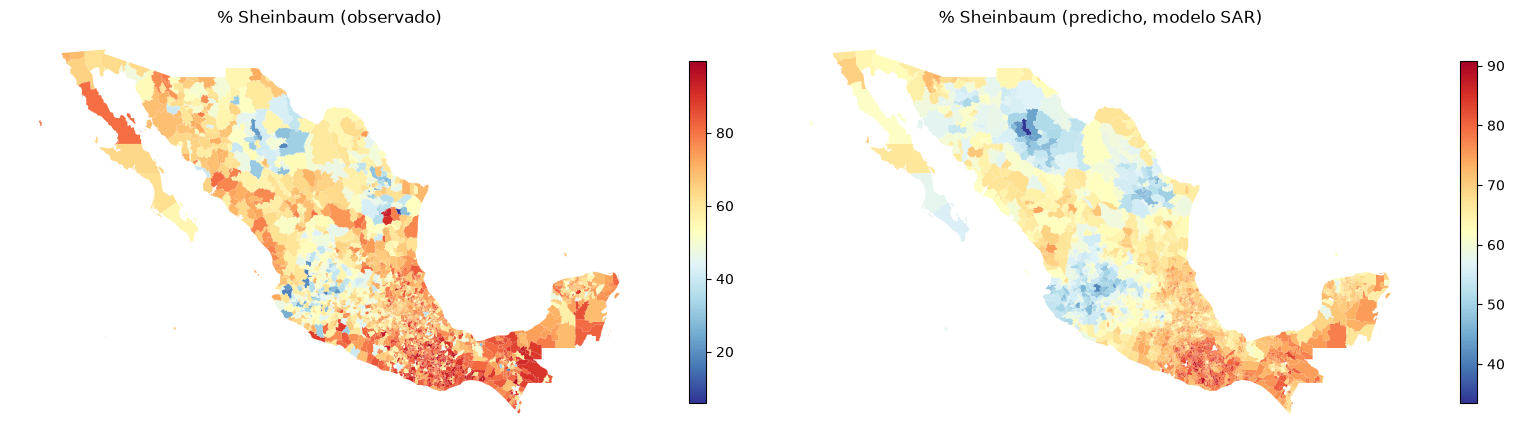

In [6]:
g["pred_sar"] = sar.predy.flatten()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
g.plot(column="pct_sheinbaum", ax=axes[0], legend=True, cmap="RdYlBu_r",
       legend_kwds={"shrink": 0.6})
axes[0].set_title("% Sheinbaum (observado)")
g.plot(column="pred_sar", ax=axes[1], legend=True, cmap="RdYlBu_r",
       legend_kwds={"shrink": 0.6})
axes[1].set_title("% Sheinbaum (predicho, modelo SAR)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, "mapa_modelo_sar.png"), dpi=150, bbox_inches="tight")
plt.show()